In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

print("Libraries imported successfully!")


Libraries imported successfully!


In [3]:

print(os.listdir('/content'))


['.config', 'sample_data']


In [4]:

import os

print(os.listdir('/content'))


['.config', 'sample_data']


In [5]:

import os
print(os.listdir('/content'))


['.config', 'sample_data']


In [6]:

from google.colab import files

uploaded = files.upload()


Saving zones.csv to zones.csv
Saving items.csv to items.csv
Saving workers.csv to workers.csv
Saving picks.csv to picks.csv
Saving orders.csv to orders.csv


In [7]:

import os

print(os.listdir('/content'))


['.config', 'items.csv', 'zones.csv', 'picks.csv', 'workers.csv', 'orders.csv', 'sample_data']


In [8]:

import os

print(os.listdir('/content'))


['.config', 'items.csv', 'zones.csv', 'picks.csv', 'workers.csv', 'orders.csv', 'sample_data']


In [9]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

orders = pd.read_csv('/content/orders.csv')
picks = pd.read_csv('/content/picks.csv')
items = pd.read_csv('/content/items.csv')
workers = pd.read_csv('/content/workers.csv')
zones = pd.read_csv('/content/zones.csv')

print("All five datasets loaded successfully!")


All five datasets loaded successfully!


In [10]:

datasets = {
    "Orders": orders,
    "Picks": picks,
    "Items": items,
    "Workers": workers,
    "Zones": zones
}

for name, df in datasets.items():
    print(f"\n--- {name} ---")
    print("Rows and columns:", df.shape)
    print("Column names:", df.columns.tolist())
    display(df.head())



--- Orders ---
Rows and columns: (250, 4)
Column names: ['order', 'item count', 'priority', 'timestamp']


,order,item count,priority,timestamp
0,ORD1000,5,Medium,2026-10-03 20:33:00
1,ORD1001,1,Medium,2026-10-01 05:52:00
2,ORD1002,8,High,2026-10-03 17:12:00
3,ORD1003,1,Low,2026-10-02 18:47:00
4,ORD1004,11,Low,2026-10-01 22:54:00



--- Picks ---
Rows and columns: (303, 6)
Column names: ['order', 'picker', 'zone', 'start', 'finish', 'quantity']


,order,picker,zone,start,finish,quantity
0,ORD1179,WK108,Zone-C,2026-10-02 09:20:00,2026-10-02 09:58:00,1
1,ORD1050,WK112,Zone-D,2026-10-02 18:14:00,2026-10-02 18:56:00,2
2,ORD1074,WK101,Zone-B,2026-10-03 21:55:00,2026-10-03 22:32:00,2
3,ORD1242,WK111,Zone-A,2026-10-02 15:35:00,2026-10-02 16:00:00,3
4,ORD1205,WK102,ZONE B,2026-10-02 10:10:00,2026-10-02 10:47:00,1



--- Items ---
Rows and columns: (40, 4)
Column names: ['item_id', 'category', 'size', 'storage class']


,item_id,category,size,storage class
0,ITM500,Groceries,Oversized,Slow-Moving
1,ITM501,Home Decor,Medium,Fast-Moving
2,ITM502,Electronics,Small,Slow-Moving
3,ITM503,Apparel,Small,Fast-Moving
4,ITM504,Automotive,Small,Fast-Moving



--- Workers ---
Rows and columns: (15, 3)
Column names: ['picker', 'shift', 'experience band']


,picker,shift,experience band
0,WK100,Morning,0-1 Years
1,WK101,Night,1-3 Years
2,WK102,Evening,1-3 Years
3,WK103,Evening,NaN
4,WK104,Morning,0-1 Years



--- Zones ---
Rows and columns: (10, 3)
Column names: ['zone', 'zone type', 'distance band']


,zone,zone type,distance band
0,Zone-A,High-Velocity,Near
1,Zone-B,Bulk-Storage,Far
2,Zone-C,Cold-Storage,Far
3,Zone-D,Mezzanine,Medium
4,Zone-E,High-Velocity,Near


In [11]:

# Clean the picks dataset
picks_clean = picks.copy()

picks_clean = picks_clean.drop_duplicates()

# Standardize zone names
picks_clean['zone'] = (
    picks_clean['zone']
    .astype('string')
    .str.strip()
    .str.upper()
    .str.replace(r'[\s_-]+', '', regex=True)
    .map({
        'ZONEA': 'Zone-A',
        'ZONEB': 'Zone-B',
        'ZONEC': 'Zone-C',
        'ZONED': 'Zone-D',
        'ZONEE': 'Zone-E'
    })
)

# Convert timestamps
picks_clean['start'] = pd.to_datetime(
    picks_clean['start'], errors='coerce'
)
picks_clean['finish'] = pd.to_datetime(
    picks_clean['finish'], errors='coerce'
)

# Calculate duration in minutes
picks_clean['picking_minutes'] = (
    picks_clean['finish'] - picks_clean['start']
).dt.total_seconds() / 60

print("Cleaned picks:", picks_clean.shape)
print("Missing finish times:",
      picks_clean['finish'].isna().sum())
print("Negative durations:",
      (picks_clean['picking_minutes'] < 0).sum())

display(picks_clean.head())


Cleaned picks: (300, 7)
Missing finish times: 2
Negative durations: 2


,order,picker,zone,start,finish,quantity,picking_minutes
0,ORD1179,WK108,Zone-C,2026-10-02 09:20:00,2026-10-02 09:58:00,1,38.0
1,ORD1050,WK112,Zone-D,2026-10-02 18:14:00,2026-10-02 18:56:00,2,42.0
2,ORD1074,WK101,Zone-B,2026-10-03 21:55:00,2026-10-03 22:32:00,2,37.0
3,ORD1242,WK111,Zone-A,2026-10-02 15:35:00,2026-10-02 16:00:00,3,25.0
4,ORD1205,WK102,Zone-B,2026-10-02 10:10:00,2026-10-02 10:47:00,1,37.0


In [12]:

workers_clean = workers.drop_duplicates().copy()
zones_clean = zones.drop_duplicates().copy()

# Fill missing worker experience with Unknown
workers_clean['experience_band'] = (
    workers_clean['experience_band'].fillna('Unknown')
)

# Standardize zone labels in the zone lookup table
zones_clean['zone'] = (
    zones_clean['zone']
    .astype(str)
    .str.strip()
    .str.title()
)

analysis = picks_clean.merge(
    workers_clean,
    on='picker',
    how='left',
    validate='many_to_one'
)

analysis = analysis.merge(
    zones_clean,
    on='zone',
    how='left',
    validate='many_to_one'
)

print("Combined dataset shape:", analysis.shape)
display(analysis.head())


KeyError: 'experience_band'

In [13]:

print("Workers columns:", workers.columns.tolist())
print("Workers_clean columns:", workers_clean.columns.tolist())

print("Analysis columns:", analysis.columns.tolist())


Workers columns: ['picker', 'shift', 'experience band']
Workers_clean columns: ['picker', 'shift', 'experience band']


NameError: name 'analysis' is not defined

In [14]:

# Copy the original datasets
picks_clean = picks.copy()
workers_clean = workers.copy()
zones_clean = zones.copy()

# Remove duplicate rows
picks_clean = picks_clean.drop_duplicates()
workers_clean = workers_clean.drop_duplicates()
zones_clean = zones_clean.drop_duplicates()

# Handle missing worker experience
workers_clean['experience band'] = (
    workers_clean['experience band'].fillna('Unknown')
)

# Standardize zone names in both datasets
def standardize_zone(series):
    return (
        series.astype('string')
        .str.strip()
        .str.upper()
        .str.replace(r'[\s_-]+', '', regex=True)
        .str.replace('ZONE', 'Zone-', regex=False)
    )

picks_clean['zone'] = standardize_zone(picks_clean['zone'])
zones_clean['zone'] = standardize_zone(zones_clean['zone'])

# Convert timestamps
picks_clean['start'] = pd.to_datetime(
    picks_clean['start'], errors='coerce'
)
picks_clean['finish'] = pd.to_datetime(
    picks_clean['finish'], errors='coerce'
)

# Calculate picking duration in minutes
picks_clean['picking_minutes'] = (
    picks_clean['finish'] - picks_clean['start']
).dt.total_seconds() / 60

# Merge picks with worker details
analysis = picks_clean.merge(
    workers_clean,
    on='picker',
    how='left',
    validate='many_to_one'
)

# Merge zone details
analysis = analysis.merge(
    zones_clean,
    on='zone',
    how='left',
    validate='many_to_one'
)

print("Combined dataset created successfully!")
print("Dataset shape:", analysis.shape)
print("\nColumns:", analysis.columns.tolist())

display(analysis.head())


MergeError: Merge keys are not unique in right dataset; not a many-to-one merge

In [15]:

print("Zone names in zones_clean:")
print(zones_clean['zone'].value_counts())

print("\nDuplicate zone records:")
display(
    zones_clean[
        zones_clean['zone'].duplicated(keep=False)
    ].sort_values('zone')
)


Zone names in zones_clean:
zone
Zone-A    2
Zone-B    2
Zone-C    1
Zone-D    1
Zone-E    1
Zone-F    1
Zone-G    1
Zone-H    1
Name: count, dtype: Int64

Duplicate zone records:


,zone,zone type,distance band
0,Zone-A,High-Velocity,Near
8,Zone-A,High-Velocity,Near
1,Zone-B,Bulk-Storage,Far
9,Zone-B,Bulk-Storage,Far


In [16]:

# Inspect conflicts before removing duplicate zone keys
conflicts = (
    zones_clean.groupby('zone')[['zone type', 'distance band']]
    .nunique()
)

print("Zones with conflicting details:")
display(conflicts[(conflicts > 1).any(axis=1)])

# Keep one record per zone for the lookup table
zones_unique = zones_clean.drop_duplicates(
    subset='zone', keep='first'
).copy()

print("Rows before:", len(zones_clean))
print("Rows after:", len(zones_unique))


Zones with conflicting details:


,zone type,distance band
zone,,


Rows before: 10
Rows after: 8


In [17]:

analysis = picks_clean.merge(
    workers_clean,
    on='picker',
    how='left',
    validate='many_to_one'
)

analysis = analysis.merge(
    zones_unique,
    on='zone',
    how='left',
    validate='many_to_one'
)

print("Merge successful!")
print("Dataset shape:", analysis.shape)
display(analysis.head())


Merge successful!
Dataset shape: (300, 11)


,order,picker,zone,start,finish,quantity,picking_minutes,shift,experience band,zone type,distance band
0,ORD1179,WK108,Zone-C,2026-10-02 09:20:00,2026-10-02 09:58:00,1,38.0,Evening,1-3 Years,Cold-Storage,Far
1,ORD1050,WK112,Zone-D,2026-10-02 18:14:00,2026-10-02 18:56:00,2,42.0,Night,1-3 Years,Mezzanine,Medium
2,ORD1074,WK101,Zone-B,2026-10-03 21:55:00,2026-10-03 22:32:00,2,37.0,Night,1-3 Years,Bulk-Storage,Far
3,ORD1242,WK111,Zone-A,2026-10-02 15:35:00,2026-10-02 16:00:00,3,25.0,Night,Unknown,High-Velocity,Near
4,ORD1205,WK102,Zone-B,2026-10-02 10:10:00,2026-10-02 10:47:00,1,37.0,Evening,1-3 Years,Bulk-Storage,Far


In [18]:

print("Dataset shape:", analysis.shape)

print("\nMissing values:")
print(analysis.isnull().sum())

print("\nDuplicate rows:", analysis.duplicated().sum())

print("\nNegative picking durations:",
      (analysis['picking_minutes'] < 0).sum())

display(analysis.head())


Dataset shape: (300, 11)

Missing values:
order              0
picker             0
zone               0
start              0
finish             2
quantity           0
picking_minutes    2
shift              0
experience band    0
zone type          0
distance band      0
dtype: int64

Duplicate rows: 0

Negative picking durations: 2


,order,picker,zone,start,finish,quantity,picking_minutes,shift,experience band,zone type,distance band
0,ORD1179,WK108,Zone-C,2026-10-02 09:20:00,2026-10-02 09:58:00,1,38.0,Evening,1-3 Years,Cold-Storage,Far
1,ORD1050,WK112,Zone-D,2026-10-02 18:14:00,2026-10-02 18:56:00,2,42.0,Night,1-3 Years,Mezzanine,Medium
2,ORD1074,WK101,Zone-B,2026-10-03 21:55:00,2026-10-03 22:32:00,2,37.0,Night,1-3 Years,Bulk-Storage,Far
3,ORD1242,WK111,Zone-A,2026-10-02 15:35:00,2026-10-02 16:00:00,3,25.0,Night,Unknown,High-Velocity,Near
4,ORD1205,WK102,Zone-B,2026-10-02 10:10:00,2026-10-02 10:47:00,1,37.0,Evening,1-3 Years,Bulk-Storage,Far


In [19]:

valid_analysis = analysis[
    analysis['picking_minutes'].notna()
    & (analysis['picking_minutes'] >= 0)
].copy()

print("Total records:", len(analysis))
print("Valid duration records:", len(valid_analysis))
print("Excluded from duration analysis:",
      len(analysis) - len(valid_analysis))


Total records: 300
Valid duration records: 296
Excluded from duration analysis: 4


,mean,median,count
zone,,,
Zone-C,30.157895,34.0,38
Zone-F,30.038462,29.0,26
Zone-B,29.000000,31.0,67
Zone-D,27.593750,29.0,32
Zone-G,27.548387,30.0,31
Zone-A,27.471698,27.0,53
Zone-E,27.344828,28.0,29
Zone-H,26.850000,28.5,20


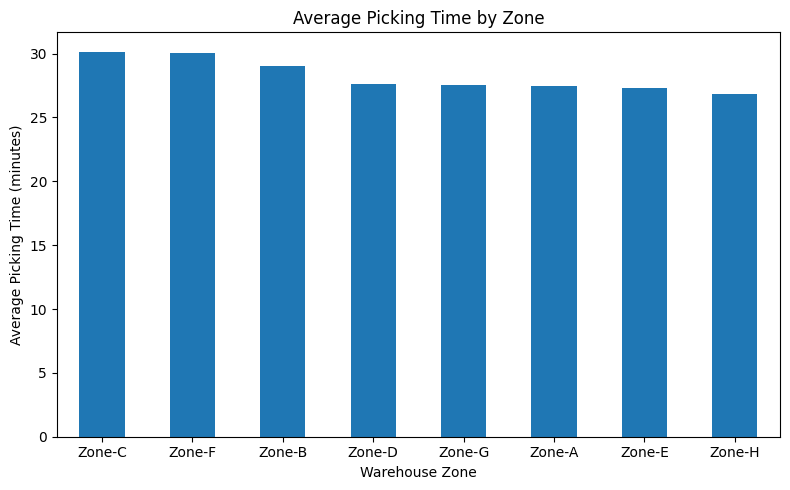

In [20]:

zone_results = (
    valid_analysis.groupby('zone')['picking_minutes']
    .agg(['mean', 'median', 'count'])
    .sort_values('mean', ascending=False)
)

display(zone_results)

zone_results['mean'].plot(
    kind='bar', figsize=(8, 5)
)
plt.title('Average Picking Time by Zone')
plt.xlabel('Warehouse Zone')
plt.ylabel('Average Picking Time (minutes)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


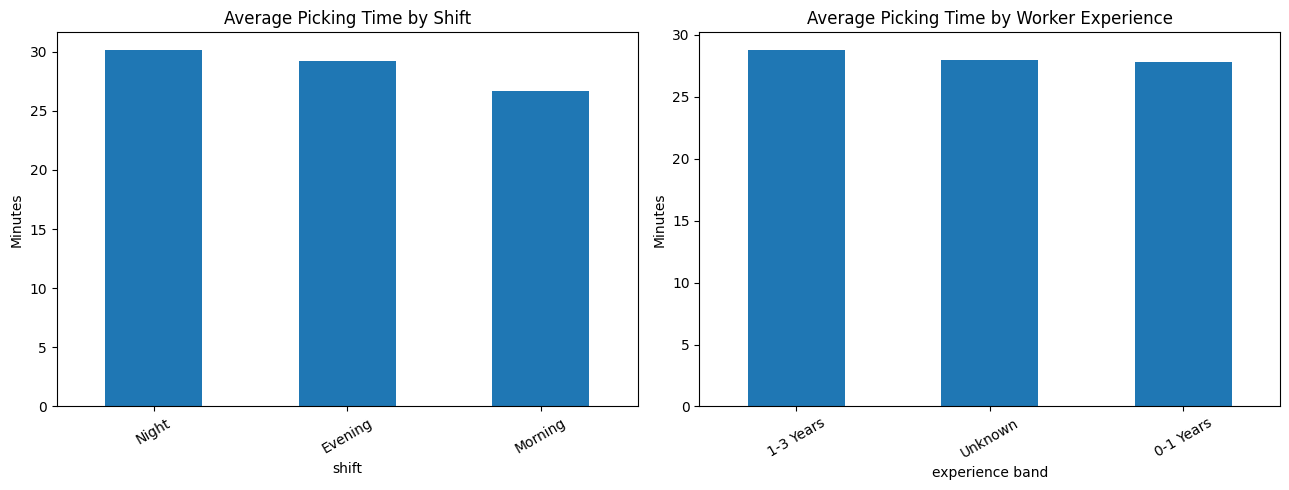

In [21]:

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

valid_analysis.groupby('shift')['picking_minutes'].mean().sort_values(
    ascending=False
).plot(kind='bar', ax=axes[0])

axes[0].set_title('Average Picking Time by Shift')
axes[0].set_ylabel('Minutes')
axes[0].tick_params(axis='x', rotation=30)

valid_analysis.groupby('experience band')['picking_minutes'].mean().sort_values(
    ascending=False
).plot(kind='bar', ax=axes[1])

axes[1].set_title('Average Picking Time by Worker Experience')
axes[1].set_ylabel('Minutes')
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()


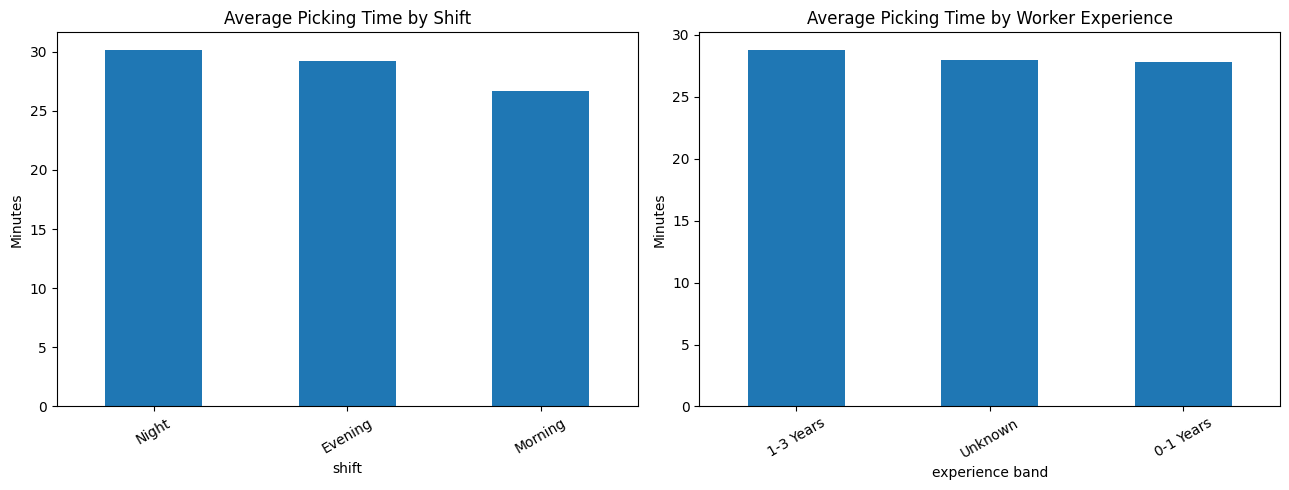

In [22]:

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

valid_analysis.groupby('shift')['picking_minutes'].mean().sort_values(
    ascending=False
).plot(kind='bar', ax=axes[0])

axes[0].set_title('Average Picking Time by Shift')
axes[0].set_ylabel('Minutes')
axes[0].tick_params(axis='x', rotation=30)

valid_analysis.groupby('experience band')['picking_minutes'].mean().sort_values(
    ascending=False
).plot(kind='bar', ax=axes[1])

axes[1].set_title('Average Picking Time by Worker Experience')
axes[1].set_ylabel('Minutes')
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()


In [23]:

analysis.to_csv('/content/warehouse_analysis.csv', index=False)

from google.colab import files
files.download('/content/warehouse_analysis.csv')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Order analysis shape: (296, 14)


,item count,mean,median,count
0,1,28.805556,30.0,36
1,2,27.958333,27.0,24
2,3,29.928571,31.0,28
3,4,28.142857,28.5,28
4,5,25.967742,26.0,31
5,6,29.758621,31.0,29
6,7,30.535714,32.0,28
7,8,25.360000,25.0,25
8,9,29.950000,33.0,20
9,10,29.515152,30.0,33


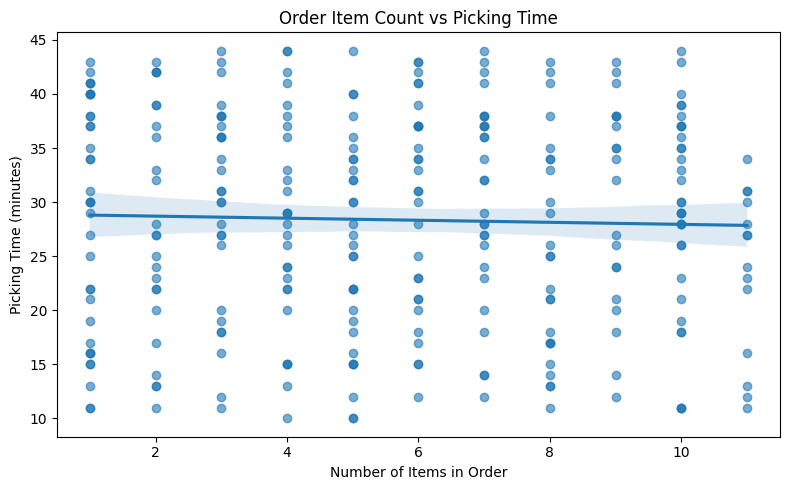

In [24]:

order_analysis = valid_analysis.merge(
    orders,
    on='order',
    how='left',
    suffixes=('', '_order')
)

print("Order analysis shape:", order_analysis.shape)

order_size_results = (
    order_analysis.groupby('item count')['picking_minutes']
    .agg(['mean', 'median', 'count'])
    .reset_index()
    .sort_values('item count')
)

display(order_size_results)

plt.figure(figsize=(8, 5))
sns.regplot(
    data=order_analysis,
    x='item count',
    y='picking_minutes',
    scatter_kws={'alpha': 0.6}
)
plt.title('Order Item Count vs Picking Time')
plt.xlabel('Number of Items in Order')
plt.ylabel('Picking Time (minutes)')
plt.tight_layout()
plt.show()


In [25]:

print("Picks columns:", picks.columns.tolist())
print("Items columns:", items.columns.tolist())


Picks columns: ['order', 'picker', 'zone', 'start', 'finish', 'quantity']
Items columns: ['item_id', 'category', 'size', 'storage class']


In [26]:

# Create a copy for feature engineering
feature_data = valid_analysis.copy()

# Add start-hour feature
feature_data['start_hour'] = (
    feature_data['start'].dt.hour
)

# Add day-of-week feature
feature_data['day_of_week'] = (
    feature_data['start'].dt.day_name()
)

# Flag longer picking durations using the dataset median
median_time = feature_data['picking_minutes'].median()

feature_data['long_pick'] = (
    feature_data['picking_minutes'] > median_time
).astype(int)

print("Median picking time:", median_time, "minutes")
print("\nEngineered features:")
display(feature_data[
    ['order', 'zone', 'shift', 'experience band',
     'picking_minutes', 'start_hour',
     'day_of_week', 'long_pick']
].head())


Median picking time: 29.0 minutes

Engineered features:


,order,zone,shift,experience band,picking_minutes,start_hour,day_of_week,long_pick
0,ORD1179,Zone-C,Evening,1-3 Years,38.0,9,Friday,1
1,ORD1050,Zone-D,Night,1-3 Years,42.0,18,Friday,1
2,ORD1074,Zone-B,Night,1-3 Years,37.0,21,Saturday,1
3,ORD1242,Zone-A,Night,Unknown,25.0,15,Friday,0
4,ORD1205,Zone-B,Evening,1-3 Years,37.0,10,Friday,1


Correlation matrix:


,picking_minutes,quantity,start_hour
picking_minutes,1.000000,-0.048042,0.064209
quantity,-0.048042,1.000000,-0.049296
start_hour,0.064209,-0.049296,1.000000


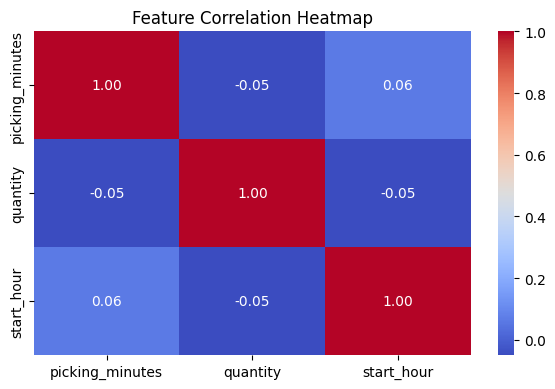

In [27]:

# Compare numerical variables with picking duration
numeric_features = feature_data[
    ['picking_minutes', 'quantity', 'start_hour']
].corr(numeric_only=True)

print("Correlation matrix:")
display(numeric_features)

plt.figure(figsize=(6, 4))
sns.heatmap(
    numeric_features,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)
plt.title('Feature Correlation Heatmap')
plt.tight_layout()
plt.show()


In [28]:

feature_data.to_csv(
    '/content/warehouse_feature_engineered.csv',
    index=False
)

from google.colab import files
files.download('/content/warehouse_feature_engineered.csv')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [29]:

# Select features relevant to warehouse picking time
selected_features = [
    'picking_minutes',
    'zone',
    'shift',
    'experience band',
    'quantity',
    'start_hour',
    'day_of_week',
    'long_pick'
]

feature_selection = feature_data[selected_features].copy()

print("Selected features:")
print(feature_selection.columns.tolist())

print("\nDataset shape:", feature_selection.shape)
display(feature_selection.head())


Selected features:
['picking_minutes', 'zone', 'shift', 'experience band', 'quantity', 'start_hour', 'day_of_week', 'long_pick']

Dataset shape: (296, 8)


,picking_minutes,zone,shift,experience band,quantity,start_hour,day_of_week,long_pick
0,38.0,Zone-C,Evening,1-3 Years,1,9,Friday,1
1,42.0,Zone-D,Night,1-3 Years,2,18,Friday,1
2,37.0,Zone-B,Night,1-3 Years,2,21,Saturday,1
3,25.0,Zone-A,Night,Unknown,3,15,Friday,0
4,37.0,Zone-B,Evening,1-3 Years,1,10,Friday,1


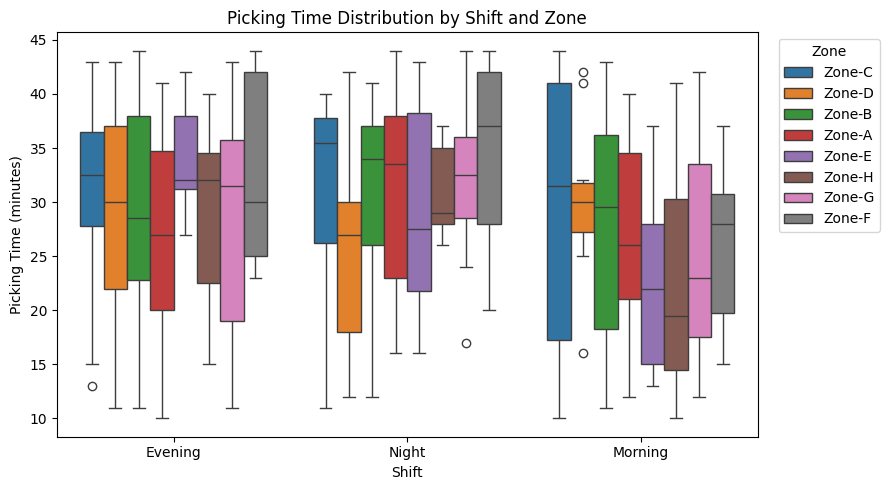

In [30]:

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=feature_data,
    x='shift',
    y='picking_minutes',
    hue='zone'
)

plt.title('Picking Time Distribution by Shift and Zone')
plt.xlabel('Shift')
plt.ylabel('Picking Time (minutes)')
plt.legend(title='Zone', bbox_to_anchor=(1.02, 1),
           loc='upper left')
plt.tight_layout()
plt.show()


In [31]:

# Save the prepared datasets
feature_selection.to_csv(
    '/content/warehouse_selected_features.csv',
    index=False
)

analysis.to_csv(
    '/content/warehouse_analysis.csv',
    index=False
)

picks_clean.to_csv(
    '/content/cleaned_picks.csv',
    index=False
)

print("Round 2 output files saved successfully!")


Round 2 output files saved successfully!


In [32]:

from google.colab import files

files.download('/content/warehouse_selected_features.csv')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [33]:

# Round 2 - Step 1: Encode categorical variables

categorical_columns = [
    'zone',
    'shift',
    'experience band',
    'day_of_week'
]

# Create a copy of the engineered dataset
encoded_data = feature_data.copy()

# Convert categorical values into numerical 0/1 columns
encoded_data = pd.get_dummies(
    encoded_data,
    columns=categorical_columns,
    dtype=int
)

print("Categorical encoding completed!")
print("Encoded dataset shape:", encoded_data.shape)
display(encoded_data.head())


Categorical encoding completed!
Encoded dataset shape: (296, 27)


,order,picker,start,finish,quantity,picking_minutes,zone type,distance band,start_hour,long_pick,...,zone_Zone-H,shift_Evening,shift_Morning,shift_Night,experience band_0-1 Years,experience band_1-3 Years,experience band_Unknown,day_of_week_Friday,day_of_week_Saturday,day_of_week_Thursday
0,ORD1179,WK108,2026-10-02 09:20:00,2026-10-02 09:58:00,1,38.0,Cold-Storage,Far,9,1,...,0,1,0,0,0,1,0,1,0,0
1,ORD1050,WK112,2026-10-02 18:14:00,2026-10-02 18:56:00,2,42.0,Mezzanine,Medium,18,1,...,0,0,0,1,0,1,0,1,0,0
2,ORD1074,WK101,2026-10-03 21:55:00,2026-10-03 22:32:00,2,37.0,Bulk-Storage,Far,21,1,...,0,0,0,1,0,1,0,0,1,0
3,ORD1242,WK111,2026-10-02 15:35:00,2026-10-02 16:00:00,3,25.0,High-Velocity,Near,15,0,...,0,0,0,1,0,0,1,1,0,0
4,ORD1205,WK102,2026-10-02 10:10:00,2026-10-02 10:47:00,1,37.0,Bulk-Storage,Far,10,1,...,0,1,0,0,0,1,0,1,0,0


In [34]:

# Round 2 - Step 2: Feature selection

selected_columns = [
    'order',
    'picker',
    'zone',
    'shift',
    'experience band',
    'quantity',
    'picking_minutes',
    'start_hour',
    'day_of_week',
    'long_pick'
]

selected_features = feature_data[selected_columns].copy()

print("Selected features:", selected_features.columns.tolist())
print("Selected dataset shape:", selected_features.shape)

display(selected_features.head())


Selected features: ['order', 'picker', 'zone', 'shift', 'experience band', 'quantity', 'picking_minutes', 'start_hour', 'day_of_week', 'long_pick']
Selected dataset shape: (296, 10)


,order,picker,zone,shift,experience band,quantity,picking_minutes,start_hour,day_of_week,long_pick
0,ORD1179,WK108,Zone-C,Evening,1-3 Years,1,38.0,9,Friday,1
1,ORD1050,WK112,Zone-D,Night,1-3 Years,2,42.0,18,Friday,1
2,ORD1074,WK101,Zone-B,Night,1-3 Years,2,37.0,21,Saturday,1
3,ORD1242,WK111,Zone-A,Night,Unknown,3,25.0,15,Friday,0
4,ORD1205,WK102,Zone-B,Evening,1-3 Years,1,37.0,10,Friday,1


In [35]:

# Round 2 - Step 3: Final data-quality report

quality_report = pd.DataFrame({
    'Data Type': analysis.dtypes.astype(str),
    'Missing Values': analysis.isnull().sum(),
    'Unique Values': analysis.nunique(),
})

print("Final data-quality report:")
display(quality_report)

print("Total records:", len(analysis))
print("Duplicate rows:", analysis.duplicated().sum())
print("Missing picking durations:",
      analysis['picking_minutes'].isna().sum())
print("Negative picking durations:",
      (analysis['picking_minutes'] < 0).sum())
print("Missing zone details:",
      analysis['zone type'].isna().sum())


Final data-quality report:


,Data Type,Missing Values,Unique Values
order,object,0,169
picker,object,0,15
zone,string,0,8
start,datetime64[ns],0,289
finish,datetime64[ns],2,282
quantity,int64,0,3
picking_minutes,float64,2,37
shift,object,0,3
experience band,object,0,3
zone type,object,0,6


Total records: 300
Duplicate rows: 0
Missing picking durations: 2
Negative picking durations: 2
Missing zone details: 0


In [36]:

# Round 2 - Step 4: Save final deliverables

picks_clean.to_csv(
    '/content/round2_cleaned_picks.csv', index=False
)

analysis.to_csv(
    '/content/round2_merged_analysis.csv', index=False
)

selected_features.to_csv(
    '/content/round2_selected_features.csv', index=False
)

encoded_data.to_csv(
    '/content/round2_encoded_features.csv', index=False
)

quality_report.to_csv(
    '/content/round2_data_quality_report.csv'
)

zone_summary = (
    valid_analysis.groupby('zone')['picking_minutes']
    .agg(['mean', 'median', 'count'])
    .sort_values('mean', ascending=False)
)

zone_summary.to_csv('/content/round2_zone_summary.csv')

print("Round 2 output files saved successfully!")


Round 2 output files saved successfully!


In [37]:

from google.colab import files

files.download('/content/round2_selected_features.csv')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>